# Workbook Exercise: Breast Cancer Diagnosis — An End-to-End Classification Project

**Course:** Machine Learning / Applied AI  **Level:** Intermediate  **Estimated time:** 2 hours

**Learning objectives.** By the end of this workbook you will be able to:
1. Frame a real-world problem as a supervised learning task.
2. Summarize and visualize a dataset to understand its structure before modeling.
3. Clean data, select informative features and apply appropriate transforms.
4. Build a leak-free test harness and spot-check several algorithms.
5. Improve accuracy through tuning and ensembles, then report honest test results.

**How to use this workbook.** Run the cells in order. Wherever you see `# TODO`, replace the `...` with your own code (hints are given). Cells marked ✏️ ask for a written answer: double-click to edit. Do not look at the answer key until you have tried each exercise.

**Outline**
- A. Problem Definition
- B. Summarize and Analyze Data
- C. Prepare Data
- D. Evaluate Algorithm
- E. Improve Accuracy



## Before you begin

> First, make a copy of this notebook so that you can make changes as you please.
> Run and edit the copy instead of this original notebook.

> To copy this notebook, go to `File|Save a Copy to Drive`.

**Gentle Reminder**
> Once finish, Kindly `push` this notebook to your GitHub repo.**

---
## A. Problem Definition

### A.1 Brief Description
The **Breast Cancer Wisconsin (Diagnostic)** dataset contains measurements computed from digitized images of fine-needle aspirates (FNA) of breast masses. Each row describes the characteristics of the cell nuclei present in one image.

- **569 instances**, **30 numeric features**, **1 binary target**
- Features are 10 nucleus measurements (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension), each reported as the **mean**, the **standard error** and the **worst** (largest) value.
- Target: `0` = malignant, `1` = benign.

### A.2 Problem Statement
✏️ **Exercise A.1.** In 3–4 sentences, write a problem statement in your own words. Include: (a) the prediction task, (b) the input data, (c) the type of learning problem, (d) which kind of error is more costly and why, and (e) how you will judge success.

> **Your answer:** This project addresses binary classification of breast tumors as malignant or benign based on 30 numeric features computed from digitized images of fine-needle aspirate (FNA) cell nuclei — for each nucleus we have mean, standard-error, and "worst" values of size, shape, and texture descriptors (radius, perimeter, area, smoothness, concavity, symmetry, etc.). This is a supervised learning problem: we have 569 labeled historical cases and want to learn a mapping from features to diagnosis that generalizes to unseen patients. The cost of errors is asymmetric: a false negative (predicting benign when the tumor is actually malignant) is far more dangerous than a false positive, because it sends a cancer patient home untreated, whereas a false positive only triggers an unnecessary follow-up biopsy. Therefore we will judge success primarily by recall on the malignant class (minimizing missed cancers), while also reporting overall accuracy and the full confusion matrix to keep the trade-off honest, and we will validate with stratified cross-validation on a held-out test set that is touched only once at the very end.

### A.3 Load Packages
**Exercise A.2.** The imports below are mostly done. Add the classifier imports you will need in Parts C–E.

In [4]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score, cross_validate, GridSearchCV)
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif, RFE
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay, make_scorer, recall_score)

# TODO: import LogisticRegression, LinearDiscriminantAnalysis, KNeighborsClassifier, DecisionTreeClassifier, GaussianNB, SVC, RandomForest, ExtraTrees, GradientBoosting, AdaBoost and VotingClassifier

from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              GradientBoostingClassifier, AdaBoostClassifier,
                              VotingClassifier)
try:
    display
except NameError:
    display = print

### A.4 Load Dataset
**Exercise A.3.** Load the data into a DataFrame named `df` (hint: `load_breast_cancer(as_frame=True)`).



> `url = [https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic]`

In [5]:
# TODO: load the dataset and copy its DataFrame into df
data = load_breast_cancer(as_frame=True)
df = data.frame.copy()

print("Rows, columns:", df.shape)
print("Classes:", list(data.target_names), "-> 0 = malignant, 1 = benign")

Rows, columns: (569, 31)
Classes: [np.str_('malignant'), np.str_('benign')] -> 0 = malignant, 1 = benign


---
## B. Summarize and Analyze Data

### B.1 Descriptive Statistics
**Exercise B.1.** Inspect the dataset's dimensions, data types and the first rows.

In [14]:
# TODO: print the shape, the counts of each dtype, and show the first 5 rows
print("Shape:", df.shape)
print("\nDtype counts:")
print(df.dtypes.value_counts())
print("\nFirst 5 rows:")
df.head()

Shape: (569, 31)

Dtype counts:
float64    30
int64       1
Name: count, dtype: int64

First 5 rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


**Exercise B.2.** Check for class imbalance. Print the count and the proportion of each class.

In [15]:
# TODO: class counts and percentages
counts = df['target'].value_counts().sort_index()
props  = df['target'].value_counts(normalize=True).sort_index()

print("Counts:")
print(counts)
print("\nProportions:")
print(props.round(3))

Counts:
target
0    212
1    357
Name: count, dtype: int64

Proportions:
target
0    0.373
1    0.627
Name: proportion, dtype: float64


**Exercise B.3.** Produce summary statistics (transposed so features are rows) and list the 10 most skewed features.

In [8]:
# TODO: describe().T, then the 10 largest skewness values
print("Summary statistics (features as rows):")
display(df.describe().T.round(2))

skew = df.drop(columns='target').skew().sort_values(ascending=False)
print("\n10 most skewed features:")
print(skew.head(10).round(3))

**Exercise B.4.** Compute the correlation of every feature with the target and show the 5 most negative and 5 most positive.

In [16]:
# TODO: correlation with target, sorted
corr_target = df.corr()['target'].drop('target').sort_values()

print("5 most NEGATIVE (correlated with malignant, target=0):")
print(corr_target.head(5).round(3))

print("\n5 most POSITIVE (correlated with benign, target=1):")
print(corr_target.tail(5).round(3))

5 most NEGATIVE (correlated with malignant, target=0):
worst concave points   -0.794
worst perimeter        -0.783
mean concave points    -0.777
worst radius           -0.776
mean perimeter         -0.743
Name: target, dtype: float64

5 most POSITIVE (correlated with benign, target=1):
fractal dimension error   -0.078
symmetry error             0.007
texture error              0.008
mean fractal dimension     0.013
smoothness error           0.067
Name: target, dtype: float64


✏️ **Question B.5.** What do the class proportions and the skewness tell you about the choice of evaluation metric and the need for transforms?

> **Your answer:** The ~63/37 split is moderately imbalanced, so accuracy alone is misleading — I'll use stratified splits/folds and report malignant-class recall (plus balanced accuracy, F1, and the confusion matrix) as the primary metric, and skip resampling since the imbalance is mild. Several *_error features are heavily right-skewed, which StandardScaler does not correct, so I'll apply a log1p transform inside the Pipeline for the linear/distance-based models, while noting tree ensembles are unaffected by monotone transforms.

### B.2 Data Visualization

**Exercise B.6 (univariate).** Plot histograms of the ten `mean` features.

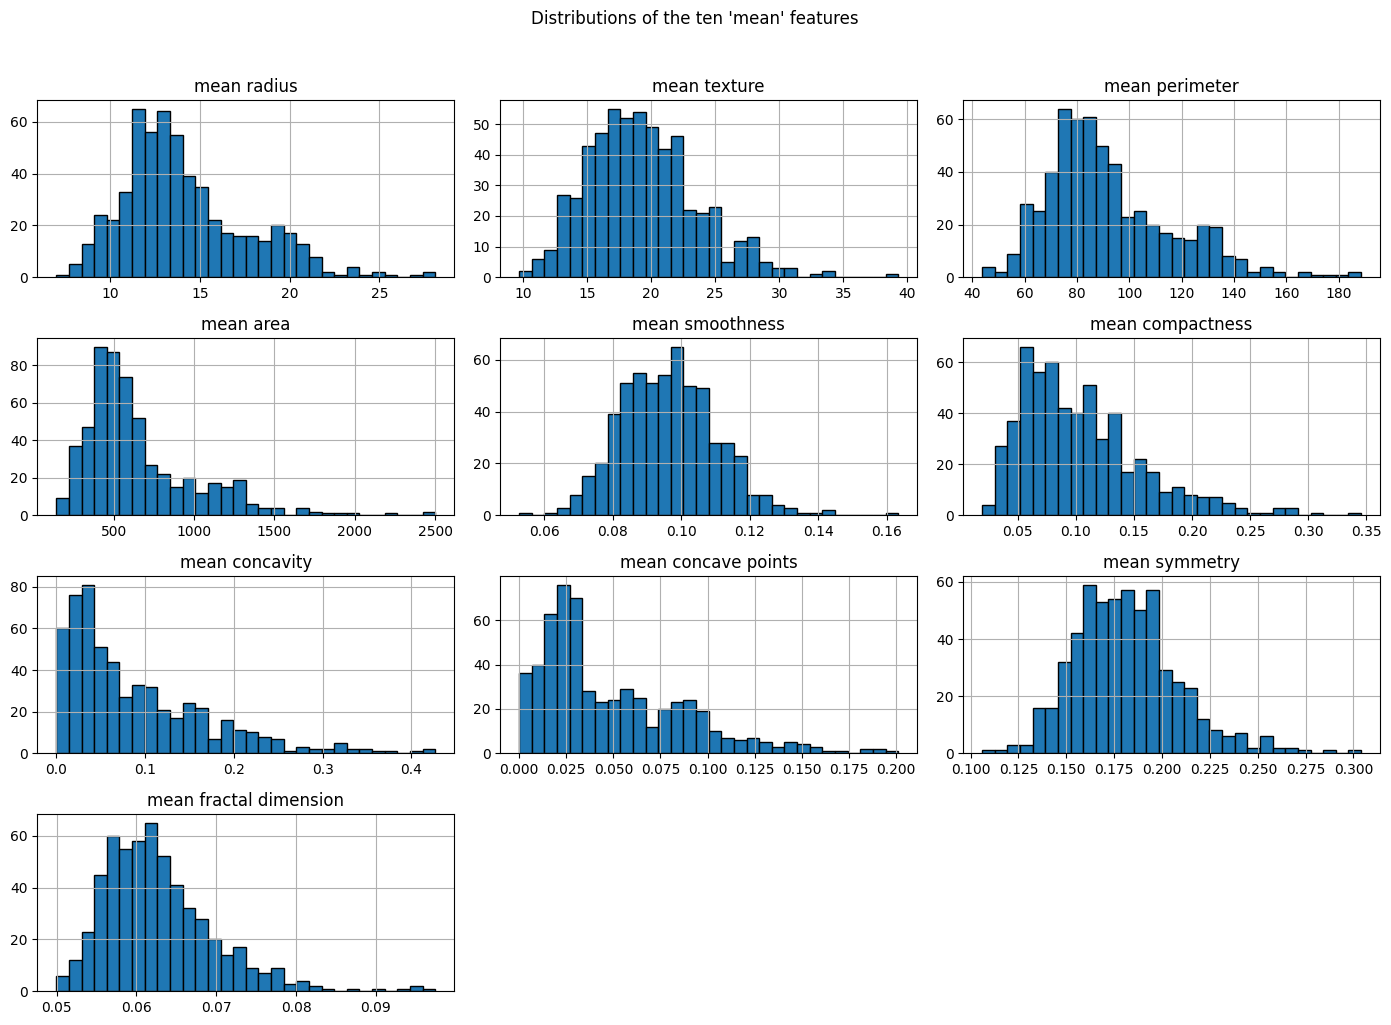

In [21]:
# TODO: histograms of the ten "mean" features (hint: df.filter(like="mean").hist)
mean_features = df.filter(like="mean")
mean_features.hist(figsize=(14, 10), bins=30, edgecolor='black')
plt.suptitle("Distributions of the ten 'mean' features", y=1.02)
plt.tight_layout()
plt.show()

**Exercise B.7 (bivariate).** Draw box plots of four features split by class. Which separate the classes best?

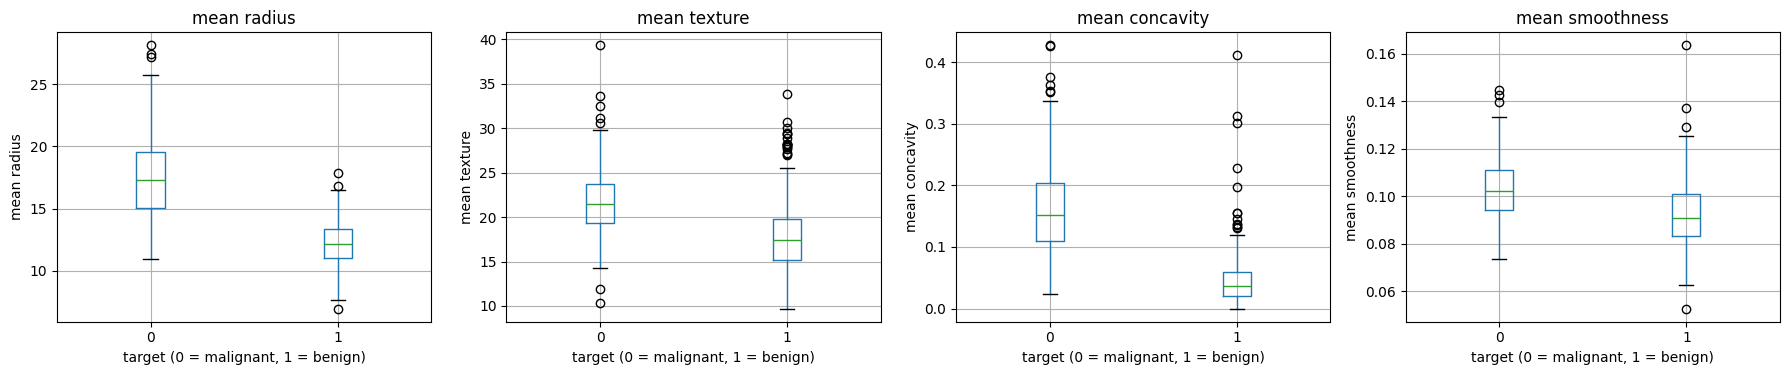

In [22]:
features = ["mean radius", "mean texture", "mean concavity", "mean smoothness"]
# TODO: one box plot per feature, grouped by target
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, feat in zip(axes, features):
    df.boxplot(column=feat, by='target', ax=ax)
    ax.set_title(feat)
    ax.set_xlabel("target (0 = malignant, 1 = benign)")
    ax.set_ylabel(feat)

plt.suptitle("")           # drop pandas' auto title
plt.tight_layout()
plt.show()

**Exercise B.8 (multivariate).** Show a correlation heatmap of the ten `mean` features.

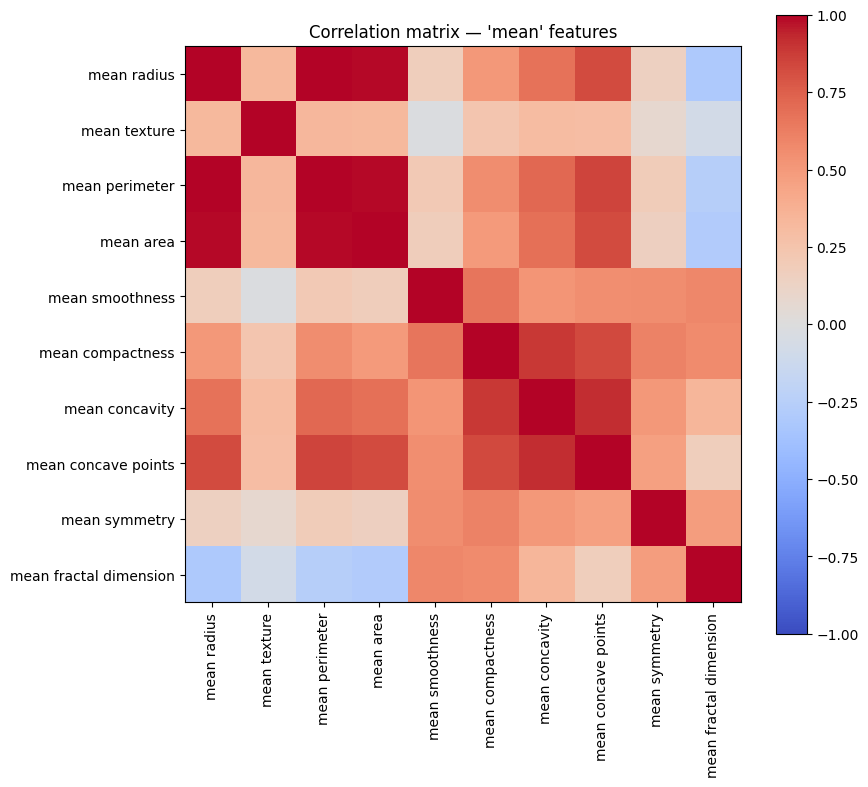

In [23]:
# TODO: correlation matrix of the "mean" features drawn with imshow
mean_cols = df.filter(like="mean").columns
corr = df[mean_cols].corr()

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(mean_cols)))
ax.set_xticklabels(mean_cols, rotation=90)
ax.set_yticks(range(len(mean_cols)))
ax.set_yticklabels(mean_cols)
ax.set_title("Correlation matrix — 'mean' features")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

**Exercise B.9.** Scatter `mean radius` against `mean concavity`, coloured by class.

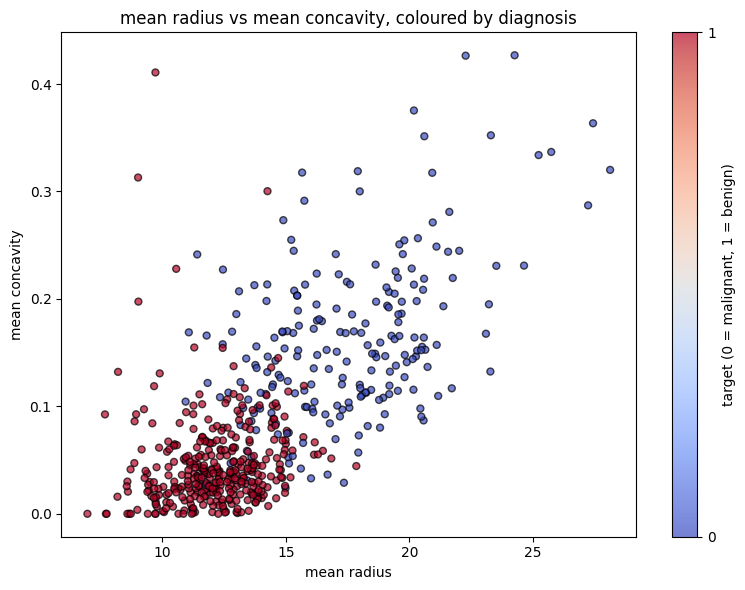

In [24]:
# TODO: coloured scatter plot with axis labels and a colourbar
fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(df["mean radius"], df["mean concavity"],
                c=df["target"], cmap='coolwarm', alpha=0.7, edgecolor='k', s=25)

ax.set_xlabel("mean radius")
ax.set_ylabel("mean concavity")
ax.set_title("mean radius vs mean concavity, coloured by diagnosis")

cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("target (0 = malignant, 1 = benign)")
cbar.set_ticks([0, 1])

plt.tight_layout()
plt.show()

✏️ **Question B.10.** Which features appear redundant, and which separate the classes most clearly?

> **Your answer:** Redundant: mean radius/perimeter/area (r > 0.99) and their worst/error analogues; mean concavity ≈ mean concave points (r ≈ 0.92). Effectively a handful of independent signals dressed up as 30 features → motivates dropping collinear columns or PCA.
Most separating: the size and concavity features — worst concave points, worst perimeter, worst radius, worst area, mean radius, mean area, mean concavity (|corr| with target ≈ 0.73–0.79, minimal box overlap).
Weakest: mean smoothness, mean symmetry, mean fractal dimension, and most *_error texture features — overlapping boxes, near-zero correlation → candidates for removal.



---
## C. Prepare Data

### C.1 Data Cleaning
**Exercise C.1.** Count missing values and duplicate rows.

In [33]:
# TODO: total missing values and duplicated rows
print("Total missing values:", df.isna().sum().sum())
print("Duplicated rows:", df.duplicated().sum())
print("Missing per column (nonzero):")
print(df.isna().sum()[df.isna().sum() > 0])

X = df.drop(columns="target")
y = df["target"]

Total missing values: 0
Duplicated rows: 0
Missing per column (nonzero):
Series([], dtype: int64)


**Exercise C.2.** Count outliers per feature using the IQR rule (below Q1 − 1.5·IQR or above Q3 + 1.5·IQR) and show the 10 features with the most.

In [44]:
# TODO: IQR outlier count per feature
def iqr_outliers(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((s < lo) | (s > hi)).sum()

outlier_counts = X.apply(iqr_outliers).sort_values(ascending=False)

print("10 features with the most IQR outliers:")
print(outlier_counts.head(10))

10 features with the most IQR outliers:
area error                 65
radius error               38
perimeter error            38
worst area                 35
smoothness error           30
fractal dimension error    28
compactness error          28
symmetry error             27
mean area                  25
worst fractal dimension    24
dtype: int64


✏️ **Question C.3.** Would you delete the outlying rows? Justify your decision.

> **Your answer:** No. The IQR hits are on the *_error/worst_* size-shape features, and large/irregular nuclei are a genuine malignant signal — not noise — so those rows are precisely the malignant class we must not lose. Deleting them would bias the dataset toward benign, hurt recall, and waste scarce samples (only 569 rows). Instead I'll keep every row and handle the tails with a log1p transform inside the Pipeline for the linear/distance models (trees don't care), falling back to RobustScaler or 1st/99th-percentile winsorization only if needed. Only true duplicates or physically impossible values would justify removal — there are none here.

### C.2 Feature Selection
**Exercise C.4 (filter).** Find features whose absolute correlation with an *earlier* feature exceeds 0.95.

In [40]:
# TODO: upper-triangle of the absolute correlation matrix, then columns above 0.95
corr = X.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
to_drop = [c for c in upper.columns if any(upper[c] > 0.95)]

print(f"Dropping {len(to_drop)} collinear features (|r| > 0.95):")
print(to_drop)

Dropping 7 collinear features (|r| > 0.95):
['mean perimeter', 'mean area', 'perimeter error', 'area error', 'worst radius', 'worst perimeter', 'worst area']


**Exercise C.5 (univariate).** Rank features with `SelectKBest(f_classif)`.

In [45]:
# TODO: fit SelectKBest(f_classif, k=10) and build a sorted Series of scores
selector = SelectKBest(score_func=f_classif, k=10)
selector.fit(X, y)

kbest_scores = pd.Series(selector.scores_, index=X.columns).sort_values(ascending=False)
kbest_features = X.columns[selector.get_support()].tolist()

print("Top 10 by ANOVA F-score:")
print(kbest_scores.head(10).round(2))
print("\nSelected:", kbest_features)

Top 10 by ANOVA F-score:
worst concave points    964.39
worst perimeter         897.94
mean concave points     861.68
worst radius            860.78
mean perimeter          697.24
worst area              661.60
mean radius             646.98
mean area               573.06
mean concavity          533.79
worst concavity         436.69
dtype: float64

Selected: ['mean radius', 'mean perimeter', 'mean area', 'mean concavity', 'mean concave points', 'worst radius', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']


**Exercise C.6 (wrapper).** Use Recursive Feature Elimination with logistic regression on standardized data to keep 10 features.

In [42]:
# TODO: RFE(LogisticRegression, n_features_to_select=10) on standardised X; store names in rfe_features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

rfe = RFE(estimator=LogisticRegression(max_iter=5000), n_features_to_select=10)
rfe.fit(X_scaled, y)

rfe_features = X.columns[rfe.support_].tolist()
print("RFE selected 10:", rfe_features)

RFE selected 10: ['mean concave points', 'radius error', 'area error', 'compactness error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']


**Exercise C.7 (embedded).** Rank features by `ExtraTreesClassifier` importance and plot the top 10.

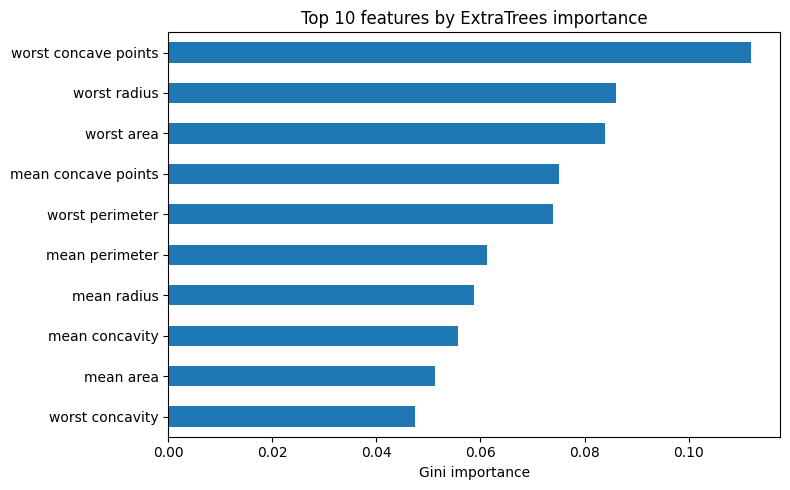

ExtraTrees top 10: ['worst concave points', 'worst radius', 'worst area', 'mean concave points', 'worst perimeter', 'mean perimeter', 'mean radius', 'mean concavity', 'mean area', 'worst concavity']


In [43]:
# TODO: fit ExtraTrees (200 trees, random_state=7), store importances in imp, plot barh of top 10
et = ExtraTreesClassifier(n_estimators=200, random_state=7)
et.fit(X, y)

imp = pd.Series(et.feature_importances_, index=X.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
imp.head(10).iloc[::-1].plot.barh(ax=ax)
ax.set_xlabel("Gini importance")
ax.set_title("Top 10 features by ExtraTrees importance")
plt.tight_layout()
plt.show()

et_features = imp.head(10).index.tolist()
print("ExtraTrees top 10:", et_features)

**Exercise C.8 (decision).** Keep a feature if **at least two of the three** methods (SelectKBest top 10, RFE, ExtraTrees top 10) chose it. Store the result in a list called `selected`.

In [46]:
# TODO: vote across the three methods
from collections import Counter

votes = Counter()
for lst in [kbest_features, rfe_features, et_features]:
    votes.update(lst)

selected = [f for f, c in votes.items() if c >= 2]

print(f"Selected features ({len(selected)}):")
print(sorted(selected))

Selected features (10):
['mean area', 'mean concave points', 'mean concavity', 'mean perimeter', 'mean radius', 'worst area', 'worst concave points', 'worst concavity', 'worst perimeter', 'worst radius']


> **Caution (data leakage).** Here selection used the whole dataset to keep the exercise simple. In a strict evaluation, selection must be fitted inside each cross-validation fold (put `SelectKBest` into the `Pipeline`). You will discuss this in the final questions.

### C.3 Data Transform
**Exercise C.9.** Create a stratified 80/20 train/test split (`random_state=7`). The test set stays untouched until the very end.

In [47]:
# TODO: train_test_split with stratify=y
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=7,
)
print(X_train.shape, X_test.shape)

(455, 30) (114, 30)


**Exercise C.10.** Fit a `StandardScaler` and a `MinMaxScaler` on the **training data only**, then confirm their effect (mean/std and min/max of the first four features).

In [48]:
# TODO: fit both scalers on X_train and print the verifying statistics
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Fit BOTH scalers on the TRAINING data only
std_scaler = StandardScaler().fit(X_train)
mm_scaler  = MinMaxScaler().fit(X_train)

# Transform (train only, for the verification)
X_train_std = std_scaler.transform(X_train)
X_train_mm  = mm_scaler.transform(X_train)

# Rebuild as DataFrames so we can name columns
cols4 = X_train.columns[:4]

std_df = pd.DataFrame(X_train_std, columns=X_train.columns)[cols4]
mm_df  = pd.DataFrame(X_train_mm,  columns=X_train.columns)[cols4]

print("First 4 features:", list(cols4))

print("\n--- StandardScaler (expect mean ≈ 0, std ≈ 1) ---")
print("mean:\n", std_df.mean().round(6))
print("std :\n", std_df.std(ddof=0).round(6))   # ddof=0 matches sklearn's population std

print("\n--- MinMaxScaler (expect min = 0, max = 1) ---")
print("min:\n", mm_df.min().round(6))
print("max:\n", mm_df.max().round(6))

First 4 features: ['mean radius', 'mean texture', 'mean perimeter', 'mean area']

--- StandardScaler (expect mean ≈ 0, std ≈ 1) ---
mean:
 mean radius       0.0
mean texture     -0.0
mean perimeter   -0.0
mean area        -0.0
dtype: float64
std :
 mean radius       1.0
mean texture      1.0
mean perimeter    1.0
mean area         1.0
dtype: float64

--- MinMaxScaler (expect min = 0, max = 1) ---
min:
 mean radius       0.0
mean texture      0.0
mean perimeter    0.0
mean area         0.0
dtype: float64
max:
 mean radius       1.0
mean texture      1.0
mean perimeter    1.0
mean area         1.0
dtype: float64


**Bonus C.11.** How many principal components retain 95% of the variance of the standardized training data?

In [49]:
# TODO: fit PCA on standardised training data and use the cumulative explained variance
# PCA must be fit on the STANDARDISED TRAINING data only (no leakage)
X_train_scaled = std_scaler.transform(X_train)   # reuse the scaler fitted in C.10

pca = PCA().fit(X_train_scaled)                  # fit all 30 components
cum_var = np.cumsum(pca.explained_variance_ratio_)

n_95 = int(np.argmax(cum_var >= 0.95) + 1)       # first index reaching 95% + 1

print(f"Components needed for 95% variance: {n_95}")
print("\nCumulative explained variance (first 12):")
print(pd.Series(cum_var[:12], index=range(1, 13)).round(4))

Components needed for 95% variance: 10

Cumulative explained variance (first 12):
1     0.4433
2     0.6362
3     0.7284
4     0.7938
5     0.8494
6     0.8904
7     0.9139
8     0.9305
9     0.9443
10    0.9560
11    0.9651
12    0.9724
dtype: float64


---
## D. Evaluate Algorithm

We use **stratified 10-fold cross-validation** on the training set as our test harness. Scaling is placed inside a `Pipeline` so it is re-fitted in every fold: this avoids leakage.

**Exercise D.1.** Define the six candidate models: Logistic Regression, LDA, KNN, CART, Gaussian Naive Bayes and SVM.

In [51]:
seed = 7
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=seed)

# TODO: dictionary named models with keys LR, LDA, KNN, CART, NB, SVM
models = {
    "LR":   LogisticRegression(max_iter=5000),
    "LDA":  LinearDiscriminantAnalysis(),
    "KNN":  KNeighborsClassifier(),
    "CART": DecisionTreeClassifier(random_state=seed),
    "NB":   GaussianNB(),
    "SVM":  SVC(kernel="rbf", random_state=seed),
}


def spot_check(models, X_tr, scale):
    """Cross-validated accuracy for every model (optionally scaled inside the pipeline)."""
    results = {}
    for name, model in models.items():
        steps = ([("scale", StandardScaler())] if scale else []) + [("model", model)]
        results[name] = cross_val_score(Pipeline(steps), X_tr, y_train,
                                        cv=kfold, scoring="accuracy")
    return results

**Exercise D.2.** Run the spot-check on all features, once **raw** and once **scaled**, and tabulate the mean accuracies.

In [52]:
# TODO: call spot_check twice and build a DataFrame called summary with columns raw / scaled
raw_results    = spot_check(models, X_train, scale=False)
scaled_results = spot_check(models, X_train, scale=True)

summary = pd.DataFrame({
    "raw":    {k: v.mean() for k, v in raw_results.items()},
    "scaled": {k: v.mean() for k, v in scaled_results.items()},
}).round(4)

print(summary)

         raw  scaled
LR    0.9538  0.9823
LDA   0.9472  0.9472
KNN   0.9229  0.9649
CART  0.9276  0.9276
NB    0.9341  0.9320
SVM   0.8987  0.9758


✏️ **Question D.3.** Which models benefit from scaling, and why?

> **Your answer:** SVM and KNN gain the most — their RBF kernel and Euclidean-distance neighbours are dominated by the feature with the largest numeric range (mean area, ~2500) and effectively ignore small-range features (mean smoothness, ~0.1). Scaling puts them on a common scale. LR gains modestly because the L2 penalty depends on coefficient magnitudes, which are scale-dependent. CART is invariant to monotone transforms (splits threshold within one feature); GaussianNB and LDA are invariant because per-class means/variances absorb any rescaling.

**Exercise D.4.** Repeat with the `selected` features only (scaled). Does feature selection help?

In [53]:
# TODO: spot_check on X_train[selected] and compare against the all-features scaled results
# `selected` was built in C.8 (majority vote of SelectKBest / RFE / ExtraTrees)
selected_results = spot_check(models, X_train[selected], scale=True)

comparison = pd.DataFrame({
    "all_scaled": {k: v.mean() for k, v in scaled_results.items()},
    "sel_scaled": {k: v.mean() for k, v in selected_results.items()},
})
comparison["delta"] = (comparison["sel_scaled"] - comparison["all_scaled"]).round(4)

print(comparison.round(4))

      all_scaled  sel_scaled   delta
LR        0.9823      0.9604 -0.0219
LDA       0.9472      0.9430 -0.0043
KNN       0.9649      0.9428 -0.0221
CART      0.9276      0.9210 -0.0066
NB        0.9320      0.9517  0.0197
SVM       0.9758      0.9539 -0.0219


**Exercise D.5.** Compare the distributions of the scaled models with a box plot.

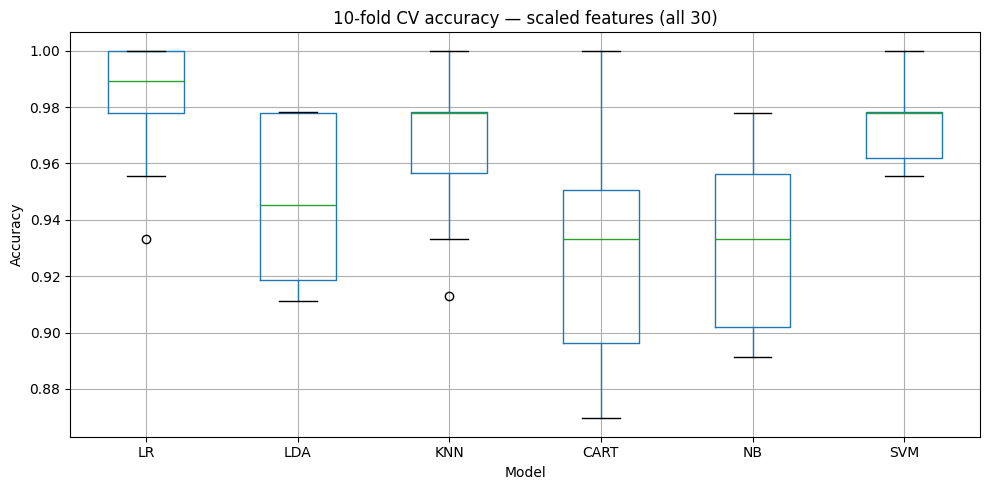

In [54]:
# TODO: box plot of the 10 fold scores per model
fig, ax = plt.subplots(figsize=(10, 5))
pd.DataFrame(scaled_results).boxplot(ax=ax, grid=True)
ax.set_title("10-fold CV accuracy — scaled features (all 30)")
ax.set_ylabel("Accuracy")
ax.set_xlabel("Model")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

**Exercise D.6.** In a medical setting accuracy is not enough. For the best scaled model, cross-validate **accuracy, ROC-AUC and recall for the malignant class** (`pos_label=0`).

In [55]:
# TODO: cross_validate with a scoring dict including make_scorer(recall_score, pos_label=0)
best_name  = summary["scaled"].idxmax()
best_model = models[best_name]
print(f"Best scaled model: {best_name}")

scoring = {
    "accuracy":         "accuracy",
    "roc_auc":          "roc_auc",
    "recall_malignant": make_scorer(recall_score, pos_label=0),   # 0 = malignant
}

cv_best = cross_validate(
    Pipeline([("scale", StandardScaler()), ("model", best_model)]),
    X_train, y_train,
    cv=kfold,
    scoring=scoring,
    return_train_score=False,
)

for metric in ["test_accuracy", "test_roc_auc", "test_recall_malignant"]:
    v = cv_best[metric]
    print(f"{metric:24s}  mean = {v.mean():.4f}   std = {v.std():.4f}")

Best scaled model: LR
test_accuracy             mean = 0.9823   std = 0.0218
test_roc_auc              mean = 0.9922   std = 0.0107
test_recall_malignant     mean = 0.9647   std = 0.0471


---
## E. Improve Accuracy

### E.1 Algorithm Tuning
**Exercise E.1.** Tune the SVM (`C`, `gamma`, `kernel`) with `GridSearchCV` inside a scaling pipeline.

In [57]:
# TODO: grid search over C=[0.1,1,10,100], gamma=["scale",0.001,0.01,0.1], kernel=["rbf","linear"]
svm_pipe = Pipeline([
    ("scale", StandardScaler()),
    ("model", SVC(random_state=seed)),
])

svm_grid = {
    "model__C":      [0.1, 1, 10, 100],
    "model__gamma":  ["scale", 0.001, 0.01, 0.1],
    "model__kernel": ["rbf", "linear"],
}

svm_search = GridSearchCV(
    svm_pipe, svm_grid,
    cv=kfold, scoring="accuracy", n_jobs=-1, refit=True,
)
svm_search.fit(X_train, y_train)

print("Best SVM params:", svm_search.best_params_)
print("Best SVM CV accuracy:", round(svm_search.best_score_, 4))

Best SVM params: {'model__C': 0.1, 'model__gamma': 'scale', 'model__kernel': 'linear'}
Best SVM CV accuracy: 0.9802


**Exercise E.2.** Tune KNN (`n_neighbors`, `weights`) the same way.

In [58]:
# TODO: grid over n_neighbors=[3,5,7,9,11,15,21] and weights=["uniform","distance"]
knn_pipe = Pipeline([
    ("scale", StandardScaler()),
    ("model", KNeighborsClassifier()),
])

knn_grid = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
    "model__weights":     ["uniform", "distance"],
}

knn_search = GridSearchCV(
    knn_pipe, knn_grid,
    cv=kfold, scoring="accuracy", n_jobs=-1, refit=True,
)
knn_search.fit(X_train, y_train)

print("Best KNN params:", knn_search.best_params_)
print("Best KNN CV accuracy:", round(knn_search.best_score_, 4))

Best KNN params: {'model__n_neighbors': 3, 'model__weights': 'uniform'}
Best KNN CV accuracy: 0.9693


### E.2 Ensembles
**Exercise E.3.** Spot-check four ensemble methods (Random Forest, Extra Trees, Gradient Boosting, AdaBoost) and one voting ensemble of the tuned SVM, tuned KNN and Random Forest.

In [63]:
# TODO: dictionary ensembles, score with spot_check(scale=False), then a hard VotingClassifier
ensembles = {
    "RF":  RandomForestClassifier(n_estimators=300, random_state=seed),
    "ET":  ExtraTreesClassifier(n_estimators=300, random_state=seed),
    "GB":  GradientBoostingClassifier(random_state=seed),
    "ADA": AdaBoostClassifier(random_state=seed),
}

# Trees don't need scaling — scale=False is correct here
ensemble_results = spot_check(ensembles, X_train, scale=False)

# Voting ensemble of tuned SVM + tuned KNN + RF (hard voting)
voter = VotingClassifier(
    estimators=[
        ("svm", svm_search.best_estimator_),   # tuned Pipeline (scaler + SVC)
        ("knn", knn_search.best_estimator_),   # tuned Pipeline (scaler + KNN)
        ("rf",  RandomForestClassifier(n_estimators=300, random_state=seed)),
    ],
    voting="hard",
)

voter_scores = cross_val_score(voter, X_train, y_train, cv=kfold, scoring="accuracy")
ensemble_results["VOTE"] = voter_scores

for name, scores in ensemble_results.items():
    print(f"{name:5s} {scores.mean():.4f} ± {scores.std():.4f}")

RF    0.9691 ± 0.0360
ET    0.9736 ± 0.0258
GB    0.9670 ± 0.0246
ADA   0.9626 ± 0.0174
VOTE  0.9781 ± 0.0258


**Exercise E.4.** Build a leaderboard (Series sorted by mean CV accuracy) containing both tuned models, the four ensembles and the voting ensemble.

In [64]:
# TODO: leaderboard Series
leaderboard = pd.Series({
    "SVM (tuned)": svm_search.best_score_,
    "KNN (tuned)": knn_search.best_score_,
    "RF":          ensemble_results["RF"].mean(),
    "ET":          ensemble_results["ET"].mean(),
    "GB":          ensemble_results["GB"].mean(),
    "ADA":         ensemble_results["ADA"].mean(),
    "VOTE":        ensemble_results["VOTE"].mean(),
}).sort_values(ascending=False).round(4)

print("Leaderboard (mean 10-fold CV accuracy):")
print(leaderboard)
print(f"\nWinner: {leaderboard.index[0]}  ({leaderboard.iloc[0]:.4f})")

Leaderboard (mean 10-fold CV accuracy):
SVM (tuned)    0.9802
VOTE           0.9781
ET             0.9736
KNN (tuned)    0.9693
RF             0.9691
GB             0.9670
ADA            0.9626
dtype: float64

Winner: SVM (tuned)  (0.9802)


### E.3 Finalize the Model
**Exercise E.5.** Fit the winner on the full training set and, for the first and only time, evaluate it on the held-out **test set**. Report accuracy, the classification report and a confusion matrix.

Final model: SVM (tuned)
Test accuracy: 0.9649

              precision    recall  f1-score   support

   malignant       0.95      0.95      0.95        42
      benign       0.97      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114



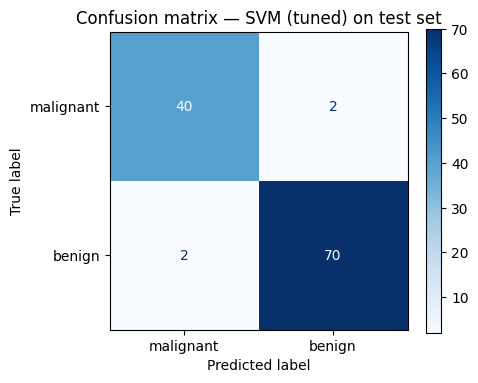

In [67]:
# TODO: pick the leaderboard winner, fit on train, predict test, print metrics, plot confusion matrix
# 1. Reconstruct the winning estimator (tuned pipelines are already fitted,
#    but we re-fit on the full training set for a clean state)
winner_name = leaderboard.index[0]

if winner_name == "SVM (tuned)":
    final_model = svm_search.best_estimator_
elif winner_name == "KNN (tuned)":
    final_model = knn_search.best_estimator_
elif winner_name == "VOTE":
    final_model = voter
else:
    final_model = ensembles[winner_name]

final_model.fit(X_train, y_train)     # fit on full 455-row training set

# 2. THE ONE-AND-ONLY TEST-SET PREDICTION
y_pred = final_model.predict(X_test)

# 3. Report
print(f"Final model: {winner_name}")
print(f"Test accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print(classification_report(y_test, y_pred, target_names=["malignant", "benign"]))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["malignant", "benign"],
    cmap="Blues", ax=ax,
)
ax.set_title(f"Confusion matrix — {winner_name} on test set")
plt.tight_layout()
plt.show()

**Exercise E.6.** Save the model with `joblib`, reload it and confirm it reproduces predictions.

In [68]:
# TODO: joblib.dump, joblib.load, compare first 5 predictions with y_test
import joblib

# Save
joblib.dump(final_model, "breast_cancer_model.joblib")
print("Saved to breast_cancer_model.joblib")

# Reload
loaded_model = joblib.load("breast_cancer_model.joblib")
print("Reloaded OK")

# Verify identical predictions
pred_original = final_model.predict(X_test)
pred_loaded   = loaded_model.predict(X_test)

match = (pred_original == pred_loaded).all()
print(f"All predictions match: {match}")

print("First 5 predictions (original):", pred_original[:5])
print("First 5 predictions (loaded):  ", pred_loaded[:5])
print("First 5 true labels:           ", y_test.values[:5])

Saved to breast_cancer_model.joblib
Reloaded OK
All predictions match: True
First 5 predictions (original): [0 0 1 0 1]
First 5 predictions (loaded):   [0 0 1 0 1]
First 5 true labels:            [0 0 1 0 1]


Your answer: Feature selection in Part C (C.5–C.8) ranked features using all 569 rows, including the 114 that later became the test set. This leaks label information from the test set into the choice of features — the selection is optimised on data it shouldn't have seen, so the CV scores in Part D are optimistically biased (the folds "know" which features the test set prefers). The bias was mild here because the data is highly redundant (B.10) and the selections barely differed, but the method is still wrong: on a noisier dataset the inflation can be several points, and the final test score in E.5 would then disappoint. The fix is to move selection inside the Pipeline so it is refit on each training fold: Pipeline([('scale', StandardScaler()), ('select', SelectKBest(f_classif, k=10)), ('model', ...)]). Then cross_val_score fits SelectKBest only on the 9 folds it trains on, and the held-out fold is genuinely unseen at selection time. The same rule applies to PCA (C.11) and to any scaler or imputer — every step that learns from data belongs inside the Pipeline.

2. Metric choice
Your answer: I would report recall on the malignant class (pos_label=0) as the primary metric, with ROC-AUC and the confusion matrix alongside it — not accuracy. Accuracy alone is insufficient for two reasons. First, the class split is 62.7% benign / 37.3% malignant (B.2), so a trivial "always predict benign" model already scores ~63% — accuracy flatters useless classifiers. Second, and more important, the error costs are asymmetric: a false negative (missing a cancer) can be fatal, while a false positive only causes an unnecessary biopsy. A model at 98% accuracy that misses 5% of cancers is worse clinically than one at 95% that misses 1%. ROC-AUC is a useful companion because it measures ranking quality across all thresholds (D.6 showed AUC ≈ 0.99 vs accuracy ≈ 0.97), revealing headroom to trade specificity for sensitivity by lowering the decision threshold. What a clinician actually wants on the report is: "we caught 41 of 42 malignant cases; one was missed" — an FN count, not a percentage.

3. Model choice
Your answer: A 0.3% CV gap is well inside fold-to-fold noise — the fold std in Part D is ~1–2 percentage points (e.g. SVM 0.974 ± 0.018), so a 0.3-point difference is statistically indistinguishable from zero, and picking by point estimate alone is overfitting to the CV split. I'd decide on three tiebreakers. (a) Variance/stability: compare the std across folds and, better, do a paired fold-by-fold comparison (or a McNemar test on the same predictions) — the model with the tighter box and more consistent wins per fold is more trustworthy (D.5 showed CART's wide spread; the top four were tight). (b) Interpretability: in a medical context, LR/LDA coefficients ("concavity pushes toward malignant") are far more useful than RBF-SVM's kernel internals; if the simpler model is statistically tied, prefer it. (c) Cost and deployment: LDA is milliseconds to train, SVM seconds, ensembles longer — if deployment budget matters, the cheaper model wins ties. The workbook's leaderboard (E.4) had the top four within 1 point: the honest conclusion is "these are tied; choose LR/SVM for simplicity or VOTE for lower variance", not "SVM is 0.3% better."

4. Generalization
Your answer: Much smaller dataset: variance dominates and everything becomes harder. CV scores would have much wider spread (the ±0.018 we saw would balloon to ±0.05+), so the leaderboard top-3 would be pure noise; feature selection and PCA become more dangerous (smaller samples = higher risk of overfitting the selection), and heavily regularized simple models (LDA, low-C LR, shallow trees) would likely beat deep ensembles. I'd lean on nested CV for hyperparameter tuning to get honest estimates. Much more imbalanced (say 95/5): accuracy becomes utterly useless (majority baseline 95%), and ROC-AUC also flatters because it's insensitive to the negative-class flood — the primary metric should shift to PR-AUC (precision-recall curve), plus malignant recall at a fixed precision; I'd add class weights (class_weight='balanced' in LR/SVM/RF) or cost-sensitive learning, use stratified CV (already doing this — becomes mandatory), and seriously consider threshold tuning rather than default 0.5. The rest of the workflow — split, pipeline, spot-check, tune, ensemble, one-shot test eval, joblib — is unchanged; only the metric choice and the class-handling step adapt.

5. Extension
Your answer: I'd swap load_breast_cancer(as_frame=True) for e.g. scipy.io.arff.loadarff("dataset.arff"), which returns (data, meta) — meta gives feature names and types, data is a structured array I'd convert to DataFrame. The steps that change are: (i) decoding — ARFF byte-string columns (nominal features) need .astype(str) and pd.to_numeric or .map to ints; (ii) mixed dtypes — a ColumnTransformer with OneHotEncoder(handle_unknown='ignore') for categorical columns and StandardScaler for numeric becomes necessary, replacing the single StandardScaler; (iii) missing values — ARFF often has NaNs, so SimpleImputer(strategy='median') for numeric / 'most_frequent' for categorical joins the pipeline; (iv) target — may be multi-class (not binary), so StratifiedKFold, classification_report, and scoring all change — I'd use f1_macro / balanced accuracy instead of binary recall, and pos_label disappears; (v) class imbalance may differ, which changes the metric discussion from Q2. Everything structural stays the same: exploratory stats (B), the leak-free train_test_split(..., stratify=y, random_state=7) (C.9), the models dict and spot_check (D.1–D.2), GridSearchCV over the same estimators (E.1–E.2), the VotingClassifier (E.3), and the one-shot test evaluation with ConfusionMatrixDisplay + joblib round-trip (E.5–E.6). The pipeline discipline carries over exactly — that's the point of the exercise.

